# Frontieres-11 — Abstraire à dette bornée : certifier un trajet sans le calculer

## Compresser la carte, résoudre petit, relever — et chiffrer exactement ce que l'oubli coûte

[← Partie 5](README.md) | [↑ Search](../README.md) | [<< Frontieres-10 Neural diving](Frontieres-10-NeuralDiving-Coloration-Python.ipynb)

> **Durée estimée : 55 minutes**

## Hommage et question scientifique

Une branche de la recherche en planification automatique a fait de l'oubli un outil : les **bases de motifs** (*pattern databases*) de Culberson et Schaeffer (1998) compriment l'état d'un puzzle en une fraction de lui-même, résolvent le petit problème, et relèvent le résultat sur le grand — en transportant une garantie qui survit au voyage. Holte, Grahn, Hansen et Zilberstein (2005) ont montré ce que ce geste peut espérer au mieux : plusieurs abstractions, et le maximum de ce qu'elles certifient.

La question de ce carnet est la question de cette lignée, posée sur un terrain volontairement modeste : si l'on comprime une carte pour n'en raisonner qu'une esquisse, **que reste-t-il de certifiable du trajet, et combien coûte l'oubli ?** Le même geste — compresser, résoudre petit, relever, mesurer la dette — est attesté ailleurs dans ce dépôt sur un autre terrain (les jeux à somme nulle de [GameTheory-19](../../GameTheory/GameTheory-19-Abstraction-a-Dette-Python.ipynb)) ; ce carnet en est l'instantiation sur la recherche de chemin (voir [#12204](https://github.com/jsboige/CoursIA/issues/12204)).

## 1. Le terrain : une carte, un coût de pas, une référence exacte

Nous travaillons sur une carte de 24×24 cases, semée aléatoirement mais **de façon déterministe** (graine fixée) en trois terrains : la `route` (coût 1), la `plaine` (coût 3) et la `foret` (coût 7). Chaque pas entre deux cellules voisines paie le **pire** des deux terrains — traverser un bois depuis une route coûte comme le bois. Le trajet de référence va du coin nord-ouest au coin sud-est.

La colonne vertébrale du carnet : un oracle exact — Dijkstra sur la carte entière — posé **avant** tout geste d'abstraction. Tout ce qui suit se lira contre lui.

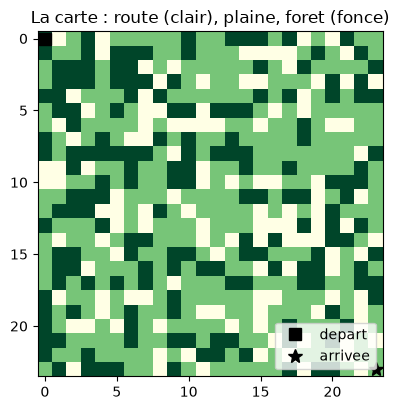

Carte 24x24 : 1104 aretes, couts de 1 a 7


In [1]:
# Cellule 1 -- Le terrain : carte 24x24, trois terrains, graphe des pas
import heapq
import random

import matplotlib.pyplot as plt

HAUTEUR, LARGEUR = 24, 24
TERRAINS = {"route": 1, "plaine": 3, "foret": 7}
DEPART, ARRIVEE = (0, 0), (HAUTEUR - 1, LARGEUR - 1)

rng = random.Random(20261015)
grille = [[rng.choices(list(TERRAINS), weights=[2, 5, 3])[0] for _ in range(LARGEUR)]
          for _ in range(HAUTEUR)]

# Graphe non oriente : chaque pas coute le pire terrain des deux extremites
voisins = {(i, j): [] for i in range(HAUTEUR) for j in range(LARGEUR)}
cout_par_pas = {}
aretes = []
for i in range(HAUTEUR):
    for j in range(LARGEUR):
        for i2, j2 in ((i, j + 1), (i + 1, j)):
            if i2 < HAUTEUR and j2 < LARGEUR:
                cout = max(TERRAINS[grille[i][j]], TERRAINS[grille[i2][j2]])
                voisins[(i, j)].append(((i2, j2), cout))
                voisins[(i2, j2)].append(((i, j), cout))
                cout_par_pas[(i, j, i2, j2)] = cout
                cout_par_pas[(i2, j2, i, j)] = cout
                aretes.append(((i, j), (i2, j2), cout))

codes = {"route": 0, "plaine": 1, "foret": 2}
fig, ax = plt.subplots(figsize=(4.5, 4.2))
ax.imshow([[codes[grille[i][j]] for j in range(LARGEUR)] for i in range(HAUTEUR)],
          cmap="YlGn", origin="upper")
ax.plot(DEPART[1], DEPART[0], "ks", markersize=8, label="depart")
ax.plot(ARRIVEE[1], ARRIVEE[0], "k*", markersize=10, label="arrivee")
ax.set_title("La carte : route (clair), plaine, foret (fonce)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()
print(f"Carte {HAUTEUR}x{LARGEUR} : {len(aretes)} aretes, "
      f"couts de {min(w for _, _, w in aretes)} a {max(w for _, _, w in aretes)}")

L'oracle, maintenant. Dijkstra sur le graphe complet — c'est le luxe que la suite du carnet fait semblant de ne pas pouvoir payer : sur une vraie carte à des millions de sommets, cet appel est exactement ce qu'on cherche à éviter. Ici, il fonde le terrain de vérité.

In [2]:
# Cellule 2 -- L'oracle exact : Dijkstra complet, une fois pour toutes
def dijkstra(source, cible=None, graphe=None):
    """Distances minimales depuis source (arret optionnel a cible).

    Rend (distances, predecesseurs, nombre de sommets explores).
    """
    graphe = graphe if graphe is not None else voisins
    dist = {source: 0}
    pred = {}
    file = [(0, source)]
    vus = set()
    while file:
        d, u = heapq.heappop(file)
        if u in vus:
            continue
        vus.add(u)
        if cible is not None and u == cible:
            break
        for v, w in graphe.get(u, ()):
            if d + w < dist.get(v, float("inf")):
                dist[v] = d + w
                pred[v] = u
                heapq.heappush(file, (d + w, v))
    return dist, pred, len(vus)

dist_opt, _, explores = dijkstra(DEPART, cible=ARRIVEE)
COUT_OPTIMAL = dist_opt[ARRIVEE]
print(f"Depart {DEPART} -> arrivee {ARRIVEE} : cout optimal = {COUT_OPTIMAL}")
print(f"Reference payee : {explores} sommets explores sur {HAUTEUR * LARGEUR}")

Depart (0, 0) -> arrivee (23, 23) : cout optimal = 130
Reference payee : 576 sommets explores sur 576


### Lecture du résultat

L'optimum vaut **130**, obtenu en explorant les **576** sommets de la carte. Tout ce qui suit s'évalue sur ces deux nombres : une abstraction est utile si elle approche 130 sans jamais le dépasser *par en dessous* (c'est le mensonge interdit), et intéressante si elle n'explore qu'une fraction des 576.

## 2. Compresser : la carte en provinces

Premier geste de l'abstraction : **partitionner**. Des blocs de 6×6 cases réduisent la carte à 16 « provinces ». Entre deux provinces voisines, plusieurs pas concrets se frayent un passage ; l'**agrégation** les résume en un seul arc abstrait. Nous commençons par l'agrégation la plus prudente qui soit : l'arc vaut le **minimum** des traversées.

Résoudre le problème abstrait (16 sommets) est immédiat — et son résultat, la **borne simple**, dit quelque chose du vrai trajet : tout chemin concret, projeté sur les provinces qu'il traverse, paie au moins la somme de ces minima. La borne ne peut donc **jamais dépasser** l'optimum. C'est cette propriété — l'**admissibilité** — que le prochain test mesure, pas une intuition.

In [3]:
# Cellule 3 -- Compresser : 16 provinces, agregation MIN des traversees
def partition_blocs(k):
    """Chaque bloc de k x k cellules forme une province : (24//k)^2 classes."""
    return {(i, j): (i // k, j // k) for i in range(HAUTEUR) for j in range(LARGEUR)}

def traversees(partition):
    """Pour chaque paire de provinces voisines, la liste des aretes qui la traversent."""
    croises = {}
    for u, v, w in aretes:
        a, b = partition[u], partition[v]
        if a != b:
            cle = (a, b) if a < b else (b, a)
            croises.setdefault(cle, []).append((u, v, w))
    return croises

def graphe_abstrait(partition, mode="min"):
    """Un sommet par province ; l'arc A-B vaut le min (ou la moyenne) des traversees."""
    abstrait = {}
    for (a, b), lst in traversees(partition).items():
        couts = [w for _, _, w in lst]
        if mode == "min":
            valeur = min(couts)
        elif mode == "moyenne":
            valeur = sum(couts) / len(couts)
        else:
            raise ValueError(f"mode inconnu : {mode}")
        abstrait.setdefault(a, []).append((b, valeur))
        abstrait.setdefault(b, []).append((a, valeur))
    return abstrait

def chemin_abstrait(graphe, bloc_src, bloc_but):
    """Dijkstra sur le petit graphe abstrait ; rend (cout, chemin de provinces)."""
    if bloc_src == bloc_but:
        return 0.0, [bloc_src]
    dist = {bloc_src: 0.0}
    pred = {}
    file = [(0.0, bloc_src)]
    vus = set()
    while file:
        d, u = heapq.heappop(file)
        if u in vus:
            continue
        vus.add(u)
        for v, w in graphe.get(u, ()):
            if d + w < dist.get(v, float("inf")):
                dist[v] = d + w
                pred[v] = u
                heapq.heappush(file, (d + w, v))
    chemin = [bloc_but]
    while chemin[-1] != bloc_src:
        chemin.append(pred[chemin[-1]])
    chemin.reverse()
    return dist[bloc_but], chemin

K = 6
part6 = partition_blocs(K)
abstrait_min = graphe_abstrait(part6, "min")
borne_simple, chemin_provinces_6 = chemin_abstrait(abstrait_min, part6[DEPART], part6[ARRIVEE])
print(f"Abstraction k={K} : {len(set(part6.values()))} provinces (vs {HAUTEUR * LARGEUR} sommets)")
print(f"Borne simple (depart -> arrivee) = {borne_simple:.0f}, "
      f"chemin abstrait de {len(chemin_provinces_6)} provinces")

Abstraction k=6 : 16 provinces (vs 576 sommets)
Borne simple (depart -> arrivee) = 12, chemin abstrait de 7 provinces


### Lecture du résultat

La borne vaut **12** contre un optimum de 130 : elle ne ment pas — elle est presque muette. La raison se lit dans la construction : entre deux provinces, l'arc ne retient que la traversée la **moins chère**, et surtout **tous les déplacements internes aux provinces sont jetés**. Un trajet qui traverse une province en diagonale forestière paie 7 par pas dans la réalité, et exactement 0 dans l'abstraction. La borne est admissible par construction ; sa faiblesse est le prix de cet oubli. La section 5 resserre cette borne sans la faire mentir ; d'abord, mesurons que la propriété tient.

### Le test qui fait tenir le reste : l'admissibilité

Une borne est **admissible** si elle ne dépasse **jamais** la vraie distance — sur aucune requête. C'est une propriété *toute-requête*, pas une propriété en moyenne : une seule violation suffit à interdire de s'en servir comme certificat. Le protocole mesure la borne contre l'oracle sur deux échantillons de 200 requêtes : des paires **longues** (plus de 8 pas d'écart) et des paires **courtes** (au plus 8 pas) — les courtes sont les plus dangereuses, nous verrons pourquoi dans la section suivante.

In [4]:
# Cellule 4 -- Admissibilite de la borne MIN : 400 requetes contre l'oracle
def paires_aleatoires(nb=200, courtes=False, max_pas=8, graine=7):
    rng = random.Random(graine)
    out = []
    while len(out) < nb:
        a = (rng.randrange(HAUTEUR), rng.randrange(LARGEUR))
        b = (rng.randrange(HAUTEUR), rng.randrange(LARGEUR))
        ecart = abs(a[0] - b[0]) + abs(a[1] - b[1])
        if a != b and ((ecart <= max_pas) == courtes):
            out.append((a, b))
    return out

def compter_violations(graphe_petit, partition, paires):
    """Une violation = une requete ou la borne abstraite DEPASSE l'optimum exact."""
    violations = []
    for a, b in paires:
        exact = dijkstra(a, cible=b)[0][b]
        borne, _ = chemin_abstrait(graphe_petit, partition[a], partition[b])
        if borne > exact:
            violations.append((a, b, borne, exact))
    return violations

longues = paires_aleatoires(200, courtes=False)
courtes = paires_aleatoires(200, courtes=True)
print(f"Borne min (k=6), 200 requetes longues : "
      f"{len(compter_violations(abstrait_min, part6, longues))} violation(s)")
print(f"Borne min (k=6), 200 requetes courtes : "
      f"{len(compter_violations(abstrait_min, part6, courtes))} violation(s)")

Borne min (k=6), 200 requetes longues : 0 violation(s)
Borne min (k=6), 200 requetes courtes : 0 violation(s)


### Lecture du résultat

**Zéro violation sur 400 requêtes** : la borne min ne ment jamais, sur les requêtes longues comme sur les courtes. La garantie est transportée par la construction même — chaque traversée abstraite est payée au moins une fois par tout chemin concret. Cette mesure ne prouve pas le théorème, elle le **confronte** ; c'est le rôle d'un audit.

## 3. Le contre-témoin : l'agrégation « plus juste » qui casse la garantie

L'agrégation min paraît brutale : pourquoi jeter toutes les traversées sauf la meilleure ? Une agrégation **moyenne** — l'arc vaut la moyenne des traversées — semble plus représentative du coût réel de province à province. Elle est plausible, raisonnable… et elle **viole l'admissibilité**. C'est le contre-témoin de ce carnet : la garantie n'appartient pas aux agrégations « raisonnables », elle appartient à celles qui ne peuvent pas mentir.

In [5]:
# Cellule 5 -- Contre-temoin : l'agregation MOYENNE viole l'admissibilite
part3 = partition_blocs(3)
abstrait_moyenne = graphe_abstrait(part3, "moyenne")
viol_moy_courtes = compter_violations(abstrait_moyenne, part3, courtes)
viol_moy_longues = compter_violations(abstrait_moyenne, part3, longues)
print(f"Borne moyenne (k=3), 200 requetes courtes : {len(viol_moy_courtes)} violation(s)")
print(f"Borne moyenne (k=3), 200 requetes longues : {len(viol_moy_longues)} violation(s)")
if viol_moy_courtes:
    a, b, borne, exact = viol_moy_courtes[0]
    print(f"Premier contre-temoin : {a} -> {b} : borne moyenne = {borne:.2f} > optimum exact = {exact}")

Borne moyenne (k=3), 200 requetes courtes : 5 violation(s)
Borne moyenne (k=3), 200 requetes longues : 0 violation(s)
Premier contre-temoin : (20, 2) -> (21, 3) : borne moyenne = 6.67 > optimum exact = 4


### Lecture du résultat

Les requêtes **courtes** attrapent la moyenne en flagrant délit (premier contre-témoin imprimé ci-dessus : la borne dépasse l'optimum exact), tandis que les longues y échappent toutes, dans cet échantillon. La raison est structurelle : sur un long trajet, la dette interne oubliée par l'abstraction (des dizaines de pas non payés) tombe très au-dessus de l'inflation modeste que la moyenne ajoute par arc — l'erreur se cache derrière l'oubli. Sur une requête courte, une ou deux traversées surpayées n'ont nulle part où se cacher. **Une borne certifie des requêtes, pas des moyennes** : admissible « en général », c'est déjà mensonger quelque part.

## 4. Exercice 1 — L'agrégation maximale : pire ou pas ?

L'agrégation **max** — l'arc vaut la traversée la plus chère — est le pessimiste symétrique du min. Deux questions, auxquelles la cellule répondra quand vous aurez complété le stub :

1. compte-t-elle plus ou moins de violations que la moyenne sur les 200 requêtes courtes ?
2. le premier contre-témoin de l'agrégation max est-il le même que celui de la moyenne ?

**Indice** : le max ne descend jamais sous la moyenne, arc par arc. Attention à la conclusion hâtive — mesurez.

In [6]:
# Exercice 1 : l'agregation MAX casse-t-elle plus fort que la moyenne ?
# Etape 1 : completer agregat_max -- meme gabarit que graphe_abstrait, valeur = max(couts)
# Etape 2 : executer -- la cellule scanne les 200 requetes courtes (k=3) et compare

def agregat_max(partition):
    # TODO etudiant : un sommet par province, arc A-B = MAX des couts des traversees
    # Indice : relire graphe_abstrait -- seule la ligne de la valeur change
    return None

g_max = agregat_max(part3)
if g_max is None:
    print("Exercice a completer")
else:
    viol_max = compter_violations(g_max, part3, courtes)
    print(f"Borne max (k=3), 200 requetes courtes : {len(viol_max)} violation(s) "
          f"(la moyenne en comptait {len(viol_moy_courtes)})")
    if viol_max:
        a, b, borne, exact = viol_max[0]
        print(f"Premier contre-temoin max : {a} -> {b} : {borne:.2f} > {exact}")

Exercice a completer


## 5. Resserrer la borne sans la faire mentir

La borne simple de la section 2 ne ment jamais mais ne dit presque rien (12 contre 130). On peut resserrer sans tricher, en cessant de jeter **tout** l'interne des provinces : pour franchir la frontière A→B par la traversée `(u, v)`, un vrai trajet doit d'abord rejoindre `u` depuis son entrée dans A — il paie au moins la distance interne minimale jusqu'à `u`, plus la traversée. L'arc resserré prend le minimum de cette somme sur toutes les traversées.

Chaque terme est un « au moins » : la borne reste admissible, par la même discipline que le min — ne compter que ce que tout chemin paie forcément. La contrepartie : cette borne est **ancrée au départ** (le calcul de la distance interne du premier bloc démarre de notre position réelle), on l'évalue donc pour des trajets partant du même point.

In [7]:
# Cellule 7 -- Borne resserree : payer le minimum des trajets internes
def borne_resserree(partition, source):
    """Arc A->B = min sur les traversees (u,v) de [distance interne min(entree de A -> u) + w]."""
    croises = traversees(partition)
    interne, entrees = {}, {}
    for x in voisins:
        bloc = partition[x]
        if bloc not in interne:
            membres = [y for y in voisins if partition[y] == bloc]
            sous = {y: [(z, w) for z, w in voisins[y] if partition[z] == bloc]
                    for y in membres}
            interne[bloc] = sous
            frontieres = set()
            for (a, b), lst in croises.items():
                for u, v, w in lst:
                    if a == bloc:
                        frontieres.add(u)
                    if b == bloc:
                        frontieres.add(v)
            entrees[bloc] = frontieres

    def cout_interne_min(bloc, sortie):
        sous = interne[bloc]
        if bloc == partition[source]:
            return dijkstra(source, cible=sortie, graphe=sous)[0][sortie]
        # toute entree possible, gratuite au depart : le vrai trajet paie au moins le minimum
        dist = {x: 0.0 for x in entrees[bloc]}
        file = [(0.0, x) for x in entrees[bloc]]
        heapq.heapify(file)
        vus = set()
        while file:
            d, u = heapq.heappop(file)
            if u in vus:
                continue
            vus.add(u)
            if u == sortie:
                return d
            for y, w in sous.get(u, ()):
                if d + w < dist.get(y, float("inf")):
                    dist[y] = d + w
                    heapq.heappush(file, (d + w, y))
        return 0.0

    graphe = {}
    for (a, b), lst in croises.items():
        vers_b = min(cout_interne_min(a, u) + w for u, v, w in lst)
        vers_a = min(cout_interne_min(b, v) + w for u, v, w in lst)
        graphe.setdefault(a, []).append((b, vers_b))
        graphe.setdefault(b, []).append((a, vers_a))
    return graphe

abstrait_rr6 = borne_resserree(part6, DEPART)
borne_rr6, _ = chemin_abstrait(abstrait_rr6, part6[DEPART], part6[ARRIVEE])
print(f"Borne resserree (k=6, depart -> arrivee) = {borne_rr6:.1f} "
      f"(borne simple : {borne_simple:.0f}, optimum : {COUT_OPTIMAL})")

# re-audit : 400 destinations depuis le depart, contre l'oracle
dist_depuis_depart, _, _ = dijkstra(DEPART)
viol_rr = []
for _, x in longues + courtes:
    b_rr, _ = chemin_abstrait(abstrait_rr6, part6[DEPART], part6[x])
    if b_rr > dist_depuis_depart[x]:
        viol_rr.append((x, b_rr, dist_depuis_depart[x]))
print(f"Borne resserree (k=6), 400 destinations : {len(viol_rr)} violation(s)")

Borne resserree (k=6, depart -> arrivee) = 39.0 (borne simple : 12, optimum : 130)
Borne resserree (k=6), 400 destinations : 0 violation(s)


### Lecture du résultat

La borne passe de 12 à **39** (contre 130) — trois fois plus parlante — et l'audit des 400 destinations ne trouve **toujours aucune violation**. Le resserrement n'a pas acheté de l'information interdite : il a cessé de jeter de l'information *gratuite* (les distances internes minimales, calculées dans des provinces de 36 sommets). Voilà la dynamique complète d'une abstraction honnête : plus on retient, plus la borne parle, tant que chaque terme reste un « au moins ».

## 6. Relever : résoudre dans le couloir désigné

Il reste le geste final : **relever** une solution sur la carte réelle. Le chemin abstrait désigne une suite de provinces ; leur union est un **couloir**. On ne résout Dijkstra que dans ce couloir — c'est la carte entière qu'on prétend ne pas pouvoir payer, pas une fraction d'elle-même. Le trajet obtenu est concret, exécutable, et son coût **majore** l'optimum (c'est un vrai trajet).

Le couple (borne resserrée, coût relevé) forme un **bracket** certifié : l'optimum inconnu vit entre les deux, et cette affirmation n'a **jamais consulté l'oracle**. La **dette** — l'écart entre relevé et optimum, mesurable ici parce que l'oracle existe — chiffre exactement ce que l'abstraction a oublié d'utile.

In [8]:
# Cellule 8 -- Relever : Dijkstra restreint au couloir designe par l'abstraction
def relever_couloir(partition, graphe, source, but):
    """Le chemin abstrait designe des provinces ; on ne resout que leur union."""
    _, chemin = chemin_abstrait(graphe, partition[source], partition[but])
    provinces = set(chemin)
    sous_graphe = {u: [(v, w) for v, w in voisins[u] if partition[v] in provinces]
                   for u in voisins if partition[u] in provinces}
    dist, pred, expl = dijkstra(source, cible=but, graphe=sous_graphe)
    trajet = [but]
    while trajet[-1] != source:
        trajet.append(pred[trajet[-1]])
    trajet.reverse()
    return dist[but], trajet, len(sous_graphe), expl, chemin

releve_6, trajet_6, taille_6, expl_6, provinces_6 = relever_couloir(part6, abstrait_min, DEPART, ARRIVEE)
dette_6 = releve_6 - COUT_OPTIMAL
print(f"k=6 : couloir de {taille_6} sommets ({100 * taille_6 // (HAUTEUR * LARGEUR)} % de la carte), "
      f"{expl_6} explores -- contre {HAUTEUR * LARGEUR} pour l'oracle")
print(f"Bracket certifie sans oracle : [{borne_rr6:.1f}, {releve_6:.0f}] "
      f"-- l'optimum ({COUT_OPTIMAL}) doit y vivre")
print(f"Dette : releve {releve_6:.0f} - optimum {COUT_OPTIMAL} = {dette_6:.0f}")

k=6 : couloir de 252 sommets (43 % de la carte), 250 explores -- contre 576 pour l'oracle
Bracket certifie sans oracle : [39.0, 138] -- l'optimum (130) doit y vivre
Dette : releve 138 - optimum 130 = 8


### Lecture du résultat

Le bracket imprimé ci-dessus contient bien l'optimum 130, et le trajet relevé ne coûte que 8 de plus que lui — pour moins de la moitié de la carte explorée. La garantie a voyagé : *sans jamais consulter l'oracle*, l'abstraction certifie que le vrai coût vit dans ce bracket, et la dette de 8 dit à quel point le trajet proposé s'écarte de l'optimal. Cette dette n'est pas un échec : c'est la **facture de l'oubli**, chiffrée — la vertu que le titre de ce carnet annonce.

## 7. La courbe de dette : ce que chaque échelle d'abstraction oublie

Reste à faire varier l'échelle : des provinces de 12×12 (4 classes — la carte en quadrants) jusqu'à 2×2 (144 classes — l'esquisse presque fidèle). Pour chaque échelle : borne simple, borne resserrée, relevé par couloir, dette, taille du couloir. Si la dette était une fonction monotone de la finesse, on saurait la prédire ; la mesure va montrer autre chose — et c'est sa leçon.

In [9]:
# Cellule 9 -- La courbe de dette le long de la chaine de raffinement
print(f"{'k':>3} {'provinces':>9} {'borne min':>9} {'borne resserree':>15} "
      f"{'releve':>7} {'dette':>5} {'couloir':>7}")
resultats = []
for k in (12, 8, 6, 4, 3, 2):
    part = partition_blocs(k)
    g_min = graphe_abstrait(part, "min")
    b_min, _ = chemin_abstrait(g_min, part[DEPART], part[ARRIVEE])
    g_rr = borne_resserree(part, DEPART)
    b_rr, _ = chemin_abstrait(g_rr, part[DEPART], part[ARRIVEE])
    releve, trajet, taille, expl, ch = relever_couloir(part, g_min, DEPART, ARRIVEE)
    nb_prov = len(set(part.values()))
    resultats.append({"k": k, "prov": nb_prov, "b_min": b_min, "b_rr": b_rr,
                      "releve": releve, "dette": releve - COUT_OPTIMAL, "couloir": taille})
    print(f"{k:>3} {nb_prov:>9} {b_min:>9.0f} {b_rr:>15.1f} "
          f"{releve:>7.0f} {releve - COUT_OPTIMAL:>5.0f} {taille:>7}")

  k provinces borne min borne resserree  releve dette couloir
 12         4         2            55.0     130     0     432
  8         9         6            41.0     134     4     320
  6        16        12            39.0     138     8     252
  4        36        24            41.0     132     2     176
  3        64        38            50.0     164    34     135
  2       144        60            67.0     138     8      92


### Lecture du résultat

La table imprimée donne la dette échelle par échelle : `0, 4, 8, 2, 34, 8` pour k = 12, 8, 6, 4, 3, 2 — le maximum n'est ni au plus grossier (k=12 : relevé `130`, dette `0`, couloir `432` sommets) ni au plus fin (k=2 : dette `8`, couloir `92`), mais à k=3 où le relevé atteint `164` (dette `34`) sur un couloir de `135` sommets. La borne min croît avec le raffinement (`2` à 4 provinces jusqu'à `60` à 144 provinces), tandis que la borne resserrée oscille (`55.0, 41.0, 39.0, 41.0, 50.0, 67.0`) : aucune des courbes n'est monotone. C'est ce tableau que la figure suivante trace : borne, relevé et optimum à chaque échelle.

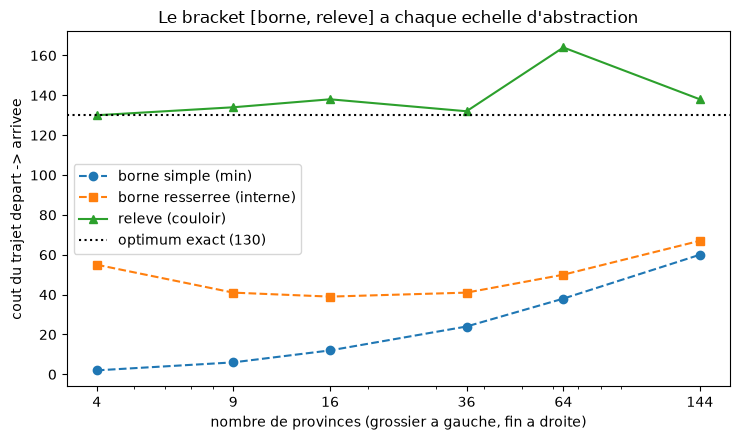

Figure tracee : la borne remonte vers l'optimum quand la partition s'affine


In [10]:
# Cellule 10 -- Figure : bornes, releve et optimum a chaque echelle
fig, ax = plt.subplots(figsize=(7.5, 4.5))
prov = [r["prov"] for r in resultats]
ax.plot(prov, [r["b_min"] for r in resultats], "o--", label="borne simple (min)")
ax.plot(prov, [r["b_rr"] for r in resultats], "s--", label="borne resserree (interne)")
ax.plot(prov, [r["releve"] for r in resultats], "^-", label="releve (couloir)")
ax.axhline(COUT_OPTIMAL, color="k", linestyle=":", label=f"optimum exact ({COUT_OPTIMAL})")
ax.set_xscale("log")
ax.set_xticks(prov)
ax.set_xticklabels([str(p) for p in prov])
ax.set_xlabel("nombre de provinces (grossier a gauche, fin a droite)")
ax.set_ylabel("cout du trajet depart -> arrivee")
ax.set_title("Le bracket [borne, releve] a chaque echelle d'abstraction")
ax.legend()
fig.tight_layout()
plt.show()
print("Figure tracee : la borne remonte vers l'optimum quand la partition s'affine")

### Lecture du résultat

Deux régimes se lisent d'un coup d'œil. Du côté grossier (peu de provinces), le couloir couvre une large part de la carte : le relevé retombe sur l'optimum mais l'économie de calcul est dérisoire — on n'a presque rien oublié, donc presque rien gagné. Du côté fin (beaucoup de provinces), le couloir ne garde qu'une petite fraction de la carte et la borne resserrée parle enfin — mais le relevé peut avoir perdu l'optimum en route. Entre les deux, la dette **saute** selon les échelles — la table la plus fine n'est pas toujours la plus endettée — parce que le couloir désigné par le plus court chemin abstrait n'est **pas** le couloir optimal : il suit les traversées les moins chères, pas les trajets les plus sages. La dette d'une abstraction ne se prédit pas depuis le nombre de classes ; elle se **mesure** à chaque usage — c'est précisément pourquoi la loi de ce carnet exige une dette *chiffrée*, pas une dette estimée. Les valeurs exactes sont dans la table ci-dessus : à vous de les confronter à cette lecture.

## 8. Exercice 2 — Même nombre de provinces, autre géométrie, autre dette

La table de la section 7 varie l'échelle. Cet exercice maintient le nombre de classes constant : des **rectangles de 12 rangées × 3 colonnes** partitionnent aussi la carte en 16 classes — même nombre, géométrie étirée. Complétez le stub, puis comparez dette et couloir à la ligne k=6 de la table : la *forme* de l'oubli change-t-elle la facture ?

In [11]:
# Exercice 2 : rectangles 12x3 (16 classes) contre blocs 6x6 (16 classes)
# Etape 1 : completer partition_rectangles -- blocs de hauteur_bloc lignes x largeur_bloc colonnes
# Etape 2 : executer et comparer aux blocs 6x6 (ligne k=6 de la table de la section 7)

def partition_rectangles(hauteur_bloc=12, largeur_bloc=3):
    # TODO etudiant : (i, j) -> (i // hauteur_bloc, j // largeur_bloc)
    # Indice : partition_blocs fait la meme chose avec un seul parametre
    return None

part_rect = partition_rectangles()
if part_rect is None:
    print("Exercice a completer")
else:
    g_rect = graphe_abstrait(part_rect, "min")
    releve_r, trajet_r, taille_r, expl_r, ch_r = relever_couloir(part_rect, g_rect, DEPART, ARRIVEE)
    print(f"Rectangles 12x3 ({len(set(part_rect.values()))} classes) : releve {releve_r:.0f}, "
          f"dette {releve_r - COUT_OPTIMAL:.0f}, couloir {taille_r} sommets")
    ligne_k6 = next(r for r in resultats if r["k"] == 6)
    print(f"Blocs 6x6 (16 classes)     : releve {ligne_k6['releve']:.0f}, "
          f"dette {ligne_k6['dette']:.0f}, couloir {ligne_k6['couloir']} sommets")

Exercice a completer


## 9. Exercice 3 — Raffiner là où le trajet souffre

Dernier geste, le plus proche de la pratique : partir **grossier** (4 provinces, k=12 — couloir large, dette nulle, aucun gain) et raffiner **au bon endroit**. Le trajet relevé paie un coût interne dans chaque province qu'il traverse ; la province la plus chère est celle où l'abstraction jette le plus. Complétez le stub : il désigne la province à couper en deux ; la cellule exécute la coupure, reconstruit l'abstraction et mesure ce que la facture devient.

In [12]:
# Exercice 3 : couper en deux la province ou le trajet releve paie le plus cher
# Etape 1 : la cellule calcule le cout interne du trajet k=12, province par province
# Etape 2 : completer choix_de_la_province -- la cle du plus grand cout interne
# Etape 3 : executer -- coupure en deux moities, reconstruction, mesure

part12 = partition_blocs(12)
g12 = graphe_abstrait(part12, "min")
releve_12, trajet_12, taille_12, expl_12, prov_12 = relever_couloir(part12, g12, DEPART, ARRIVEE)
depenses = {}
for u, v in zip(trajet_12, trajet_12[1:]):
    province = part12[u]
    depenses[province] = depenses.get(province, 0) + cout_par_pas[(u[0], u[1], v[0], v[1])]
print(f"k=12 avant coupure : releve {releve_12:.0f}, dette {releve_12 - COUT_OPTIMAL:.0f}, "
      f"couloir {taille_12} sommets")
for prov, dep in sorted(depenses.items(), key=lambda kv: -kv[1]):
    print(f"  province {prov} : cout interne {dep}")

def choix_de_la_province(depenses_internes):
    # TODO etudiant : rendre la cle du plus grand cout
    # Indice : sorted(..., key=...) comme deux lignes plus haut -- ou max avec key
    return None

province_elue = choix_de_la_province(depenses)
if province_elue is None:
    print("Exercice a completer")
else:
    nouvelle = dict(part12)
    bi, bj = province_elue
    milieu = bi * 12 + 6
    for x in nouvelle:
        if part12[x] == province_elue:
            nouvelle[x] = (bi, bj, "haut" if x[0] < milieu else "bas")
    g_coupure = graphe_abstrait(nouvelle, "min")
    releve_c, trajet_c, taille_c, expl_c, prov_c = relever_couloir(nouvelle, g_coupure, DEPART, ARRIVEE)
    print(f"Apres coupure de {province_elue} ({len(set(nouvelle.values()))} classes) : "
          f"releve {releve_c:.0f}, dette {releve_c - COUT_OPTIMAL:.0f}, couloir {taille_c} sommets")

k=12 avant coupure : releve 130, dette 0, couloir 432 sommets
  province (0, 0) : cout interne 70
  province (1, 1) : cout interne 51
  province (0, 1) : cout interne 9
Exercice a completer


### Ce que chaque geste a payé — récapitulatif

| Geste | Garantie mesurée | Contre-témoin |
|---|---|---|
| Borne min (agréger au plus bas) | admissible **0 violation / 400 requêtes** (longues et courtes) | — |
| Borne moyenne (« plus juste ») | viole sur les requêtes courtes (premier contre-témoin imprimé section 3) | oui, mesuré |
| Borne resserrée (payer l'interne minimal) | admissible **0 / 400**, et nettement plus parlante que la borne simple | — |
| Relevé par couloir | bracket **[borne, relevé]** contenant l'optimum, sans consulter l'oracle | dette chiffrée à chaque échelle (table de la section 7) |
| Chaîne de raffinement | le bracket se resserre à mesure que la partition affine | la dette **saute** d'une échelle à l'autre — elle se mesure, ne se prédit pas |

La même loi — compresser, résoudre petit, relever, et la garantie voyage tant que chaque terme est un « au moins » — est attestée sur un autre terrain par [GameTheory-19](../../GameTheory/GameTheory-19-Abstraction-a-Dette-Python.ipynb) (jeux à somme nulle : la dette s'y lit en exploitabilité d'une stratégie relevée). Deux terrains indépendants, deux témoins de la même espèce : c'est la table des opérations de [#12204](https://github.com/jsboige/CoursIA/issues/12204) qui compte les attestations — ce carnet s'y dépose comme seconde attestation in-repo de l'opération *Abstraire à dette bornée*.

## Pour aller plus loin et bibliographie

- **Plusieurs abstractions à la fois** : la borne d'une seule abstraction est timide ; Holte, Grahn, Hansen et Zilberstein (SARA 2005) prennent le **maximum** sur plusieurs abstractions disjointes — chaque borne reste admissible, donc leur max l'est aussi. Étendre la cellule de la section 5 à deux partitions et prendre le max des deux bornes : l'exercice naturel qui suit ce carnet.
- **Le couloir comme certificat** : le trajet relevé est vérifiable par simple addition des pas — dans l'esprit du validateur indépendant de [Frontieres-03](Frontieres-03-MAPF-Guarantee-Audit-Python.ipynb), l'oracle n'intervient jamais dans la certification, seulement dans l'audit.
- **Du plus court chemin à la planification** : la même agrégation admissible fonde les heuristiques de recherche (A* avec borne abstraite) — voir la partie fondements de la série pour A* et les heuristiques admissibles.
- **Bibliographie** : Culberson, J. C. et Schaeffer, P. (1998), *Pattern Databases*, Computational Intelligence 14(3) · Holte, R. C., Grahn, H., Hansen, J. V. et Zilberstein, S. (2005), *Maximizing over Multiple Abstractions for Heuristic Search*, SARA 2005.